# Exploratory Data Analysis (EDA) - Lintang Bakso Ketintang
**Dataset:** `sales_report.csv`  
**Periode Data:** Januari 2026 – September 2026  

---

### Objektif Analisis:
1. **Inspeksi Data**: Mengetahui dimensi dataset, tipe data tiap kolom, dan proporsi nilai kosong (*missing values*).
2. **Pembersihan Data (Data Cleaning)**:
   - **Menghapus (*drop*) kolom yang 100% kosong**, yaitu: `Variant`, `SKU`, dan `Served By`.
   - Mengonversi format tanggal dan waktu menjadi `Datetime`.
   - Memvalidasi kolom numerik finansial (`Quantity`, `Gross Sales`, `Discounts`, `Refunds`, `Net Sales`).
3. **Rekayasa Fitur Waktu (*Feature Engineering*)**: Membuat kolom `Month_Year`, `Day_Name`, dan `Hour`.
4. **Metrik Finansial Utama**: Menghitung omset kotor (*Gross Sales*), total diskon, refund, omset bersih (*Net Sales*), dan *Average Order Value* (AOV).
5. **Analisis Menu & Kategori**: Mengidentifikasi kategori dan menu terlaris (*Best Seller*) serta kontributor omset terbesar.
6. **Analisis Tren Waktu**: Menganalisis tren omset bulanan, pola transaksi harian (*Weekday vs Weekend*), dan jam sibuk (*Peak Hours*).
7. **Kanal & Metode Pembayaran**: Proporsi penjualan *Dine In vs Online* serta preferensi metode pembayaran.
8. **Temuan Kunci & Rekomendasi Bisnis**: Rangkuman temuan strategis untuk operasional dan pemasaran.


## 1. Setup & Import Libraries
Mengimpor library yang dibutuhkan untuk pemrosesan data (`pandas`, `numpy`) dan visualisasi data (`matplotlib`, `seaborn`).


In [1]:
# Jalankan baris di bawah jika library belum terpasang di environment Anda:
# %pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Semua library berhasil diimpor!")


Semua library berhasil diimpor!


## 2. Memuat Dataset (Data Loading)
Membaca file `sales_report.csv` ke dalam DataFrame Pandas.


In [2]:
# Load dataset
df = pd.read_csv('sales_report.csv')

print(f"Dimensi awal dataset: {df.shape[0]:,} baris dan {df.shape[1]} kolom\n")
df.head()


Dimensi awal dataset: 64,327 baris dan 25 kolom



,Outlet,Receipt Number,Date,Time,Category,Brand,Items,Variant,SKU,Quantity,...,Net Sales,Gratuity,Tax,Sales Type,Collected By,Served By,Customer,Payment Method,Event Type,Reason of Refund
0,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Gorengan,Unbranded,Goreng Panjang,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
1,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Ice Cream Aice,Aice,Miki Double Choco,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
2,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Ice Cream Aice,Aice,Coffee Crispy,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
3,Lintang Bakso Ketintang,3BOVOK,24-09-2026,21:45:23,Ice Cream Aice,Aice,Coffee Crispy,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
4,Lintang Bakso Ketintang,3BOVOK,24-09-2026,21:45:23,Ice Cream Aice,Aice,Miki Miki Stik,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN


## 3. Pemeriksaan Struktur Data & Nilai Hilang (Data Inspection)
Memeriksa tipe data awal, ringkasan informasi dataset, dan persentase nilai kosong (*missing values*) pada setiap kolom.


In [3]:
# Informasi struktur dan tipe data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64327 entries, 0 to 64326
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Outlet            64327 non-null  object 
 1   Receipt Number    64327 non-null  object 
 2   Date              64327 non-null  object 
 3   Time              64327 non-null  object 
 4   Category          64327 non-null  object 
 5   Brand             64327 non-null  object 
 6   Items             64327 non-null  object 
 7   Variant           0 non-null      float64
 8   SKU               0 non-null      float64
 9   Quantity          64327 non-null  int64  
 10  Modifier Applied  584 non-null    object 
 11  Discount Applied  7315 non-null   object 
 12  Gross Sales       64327 non-null  float64
 13  Discounts         64327 non-null  float64
 14  Refunds           64327 non-null  float64
 15  Net Sales         64327 non-null  float64
 16  Gratuity          64327 non-null  float6

In [4]:
# Pemeriksaan persentase missing values pada setiap kolom
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)


,Missing Values,Percentage (%)
Variant,64327,100.00
SKU,64327,100.00
Served By,64327,100.00
Reason of Refund,64162,99.74
Modifier Applied,63743,99.09
Discount Applied,57012,88.63
Customer,25776,40.07


## 4. Pembersihan Data (Data Cleaning & Preprocessing)
Pada tahap ini dilakukan:
1. **Drop Kolom 100% Kosong**: Kolom yang seluruh nilainya kosong/null (`Variant`, `SKU`, dan `Served By`) dihapus.
2. **Konversi Tipe Data Waktu**: Menggabungkan `Date` dan `Time` menjadi format `Datetime`.
3. **Ekstraksi Fitur Waktu**: Membuat kolom `Month_Year`, `Day_Name`, dan `Hour`.
4. **Validasi Tipe Data Numerik**: Memastikan kolom finansial (`Quantity`, `Gross Sales`, `Discounts`, `Refunds`, `Net Sales`) bertipe numerik dan mengisi nilai null dengan 0.


In [5]:
# Salin data untuk proses cleaning
df_clean = df.copy()

# 1. Hapus kolom yang benar-benar kosong (100% NaN / null)
empty_cols = df_clean.columns[df_clean.isnull().all()].tolist()
df_clean = df_clean.drop(columns=empty_cols)
print(f"Kolom yang benar-benar kosong berhasil didrop ({len(empty_cols)} kolom): {empty_cols}")
print(f"Jumlah kolom: dari {df.shape[1]} kolom menjadi {df_clean.shape[1]} kolom\n")

# 2. Konversi Date dan Time ke Datetime
df_clean['Datetime'] = pd.to_datetime(
    df_clean['Date'] + ' ' + df_clean['Time'],
    format='%d-%m-%Y %H:%M:%S',
    errors='coerce'
)
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%d-%m-%Y', errors='coerce')

# 3. Ekstraksi atribut waktu
df_clean['Month_Year'] = df_clean['Date'].dt.to_period('M')
df_clean['Day_Name'] = df_clean['Date'].dt.day_name()
df_clean['Hour'] = pd.to_datetime(df_clean['Time'], format='%H:%M:%S', errors='coerce').dt.hour

# Urutan hari dalam sepekan (Senin s/d Minggu)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_clean['Day_Name'] = pd.Categorical(df_clean['Day_Name'], categories=day_order, ordered=True)

# 4. Validasi kolom numerik keuangan
num_cols = ['Quantity', 'Gross Sales', 'Discounts', 'Refunds', 'Net Sales', 'Gratuity', 'Tax']
for col in num_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(0)

print("Data cleaning & feature engineering selesai!")
df_clean[['Receipt Number', 'Datetime', 'Category', 'Items', 'Quantity', 'Gross Sales', 'Net Sales']].head()


Kolom yang benar-benar kosong berhasil didrop (3 kolom): ['Variant', 'SKU', 'Served By']
Jumlah kolom: dari 25 kolom menjadi 22 kolom

Data cleaning & feature engineering selesai!


,Receipt Number,Datetime,Category,Items,Quantity,Gross Sales,Net Sales
0,3BOVOL,2026-09-24 21:52:08,Gorengan,Goreng Panjang,1,3000.0,0.0
1,3BOVOL,2026-09-24 21:52:08,Ice Cream Aice,Miki Double Choco,1,2000.0,0.0
2,3BOVOL,2026-09-24 21:52:08,Ice Cream Aice,Coffee Crispy,1,4000.0,0.0
3,3BOVOK,2026-09-24 21:45:23,Ice Cream Aice,Coffee Crispy,1,4000.0,0.0
4,3BOVOK,2026-09-24 21:45:23,Ice Cream Aice,Miki Miki Stik,1,2000.0,0.0


## 5. Ringkasan Metrik Finansial & Transaksi Utama
Menghitung total transaksi (struk unik), total omset kotor (*Gross Sales*), diskon, refund, omset bersih (*Net Sales*), dan *Average Order Value* (AOV).


In [6]:
# Agregasi metrik finansial
total_gross = df_clean['Gross Sales'].sum()
total_discounts = df_clean['Discounts'].sum()
total_refunds = df_clean['Refunds'].sum()
total_net = df_clean['Net Sales'].sum()
total_qty = df_clean['Quantity'].sum()
total_receipts = df_clean['Receipt Number'].nunique()

# Analisis level struk belanja (Receipt Level)
receipt_summary = df_clean.groupby('Receipt Number').agg({
    'Net Sales': 'sum',
    'Gross Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

aov = receipt_summary['Net Sales'].mean()
median_order = receipt_summary['Net Sales'].median()
avg_items_per_order = receipt_summary['Quantity'].mean()

print("=" * 60)
print("             RINGKASAN METRIK PENJUALAN")
print("=" * 60)
print(f"Total Transaksi (Struk Unik) : {total_receipts:,}")
print(f"Total Item Terjual           : {total_qty:,.0f} pcs")
print(f"Total Penjualan Kotor (Gross): Rp {total_gross:,.2f}")
print(f"Total Diskon Diberikan       : Rp {total_discounts:,.2f} ({total_discounts/total_gross*100:.2f}%)")
print(f"Total Nilai Refund           : Rp {total_refunds:,.2f}")
print(f"Total Penjualan Bersih (Net) : Rp {total_net:,.2f}")
print("-" * 60)
print(f"Average Order Value (AOV)    : Rp {aov:,.2f}")
print(f"Median Order Value           : Rp {median_order:,.2f}")
print(f"Rata-rata Item per Pesanan   : {avg_items_per_order:.2f} pcs")
print("=" * 60)


             RINGKASAN METRIK PENJUALAN
Total Transaksi (Struk Unik) : 12,238
Total Item Terjual           : 98,782 pcs
Total Penjualan Kotor (Gross): Rp 579,298,500.00
Total Diskon Diberikan       : Rp 31,900,460.40 (5.51%)
Total Nilai Refund           : Rp 1,676,000.00
Total Penjualan Bersih (Net) : Rp 545,722,042.59
------------------------------------------------------------
Average Order Value (AOV)    : Rp 44,592.42
Median Order Value           : Rp 36,000.00
Rata-rata Item per Pesanan   : 8.07 pcs


## 6. Analisis Performa Kategori Produk
Menganalisis kategori menu yang memberikan kontribusi terbesar terhadap omset bersih (*Net Sales*) dan volume kuantitas penjualan.


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_4218/163480954.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_perf, x='Net Sales', y='Category', palette='Blues_r', ax=axes[0])
/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_4218/163480954.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_perf.sort_values(by='Quantity', ascending=False), x='Quantity', y='Category', palette='Oranges_r', ax=axes[1])


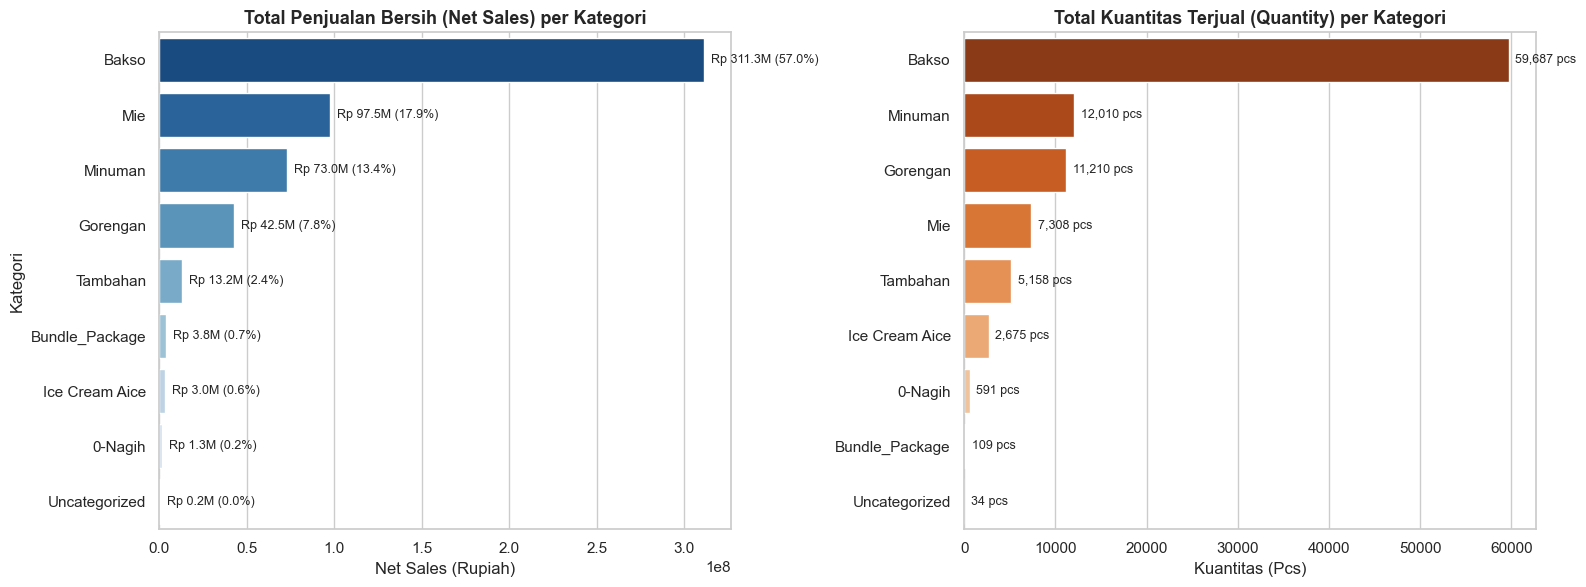

,Category,Net Sales,Quantity,Net Sales Share (%),Quantity Share (%)
0,Bakso,3.112713e+08,59687,57.04,60.42
1,Mie,9.751523e+07,7308,17.87,7.40
2,Minuman,7.296554e+07,12010,13.37,12.16
3,Gorengan,4.253663e+07,11210,7.79,11.35
4,Tambahan,1.316690e+07,5158,2.41,5.22
5,Bundle_Package,3.760200e+06,109,0.69,0.11
6,Ice Cream Aice,3.020101e+06,2675,0.55,2.71
7,0-Nagih,1.313000e+06,591,0.24,0.60
8,Uncategorized,1.731089e+05,34,0.03,0.03


In [7]:
# Agregasi performa per Kategori
category_perf = df_clean.groupby('Category').agg({
    'Net Sales': 'sum',
    'Quantity': 'sum'
}).sort_values(by='Net Sales', ascending=False).reset_index()

category_perf['Net Sales Share (%)'] = (category_perf['Net Sales'] / total_net * 100).round(2)
category_perf['Quantity Share (%)'] = (category_perf['Quantity'] / total_qty * 100).round(2)

# Visualisasi Bar Chart Berdampingan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Net Sales per Kategori
sns.barplot(data=category_perf, x='Net Sales', y='Category', palette='Blues_r', ax=axes[0])
axes[0].set_title('Total Penjualan Bersih (Net Sales) per Kategori', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Net Sales (Rupiah)')
axes[0].set_ylabel('Kategori')
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'Rp {width/1e6:.1f}M ({width/total_net*100:.1f}%)', 
                     (width, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

# Plot 2: Kuantitas per Kategori
sns.barplot(data=category_perf.sort_values(by='Quantity', ascending=False), x='Quantity', y='Category', palette='Oranges_r', ax=axes[1])
axes[1].set_title('Total Kuantitas Terjual (Quantity) per Kategori', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kuantitas (Pcs)')
axes[1].set_ylabel('')
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f'{width:,.0f} pcs', 
                     (width, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

category_perf


## 7. Analisis Menu Terlaris (Top 10 Best Sellers)
Menganalisis 10 produk dengan volume penjualan tertinggi dan 10 produk penyumbang pendapatan (*revenue*) terbesar.


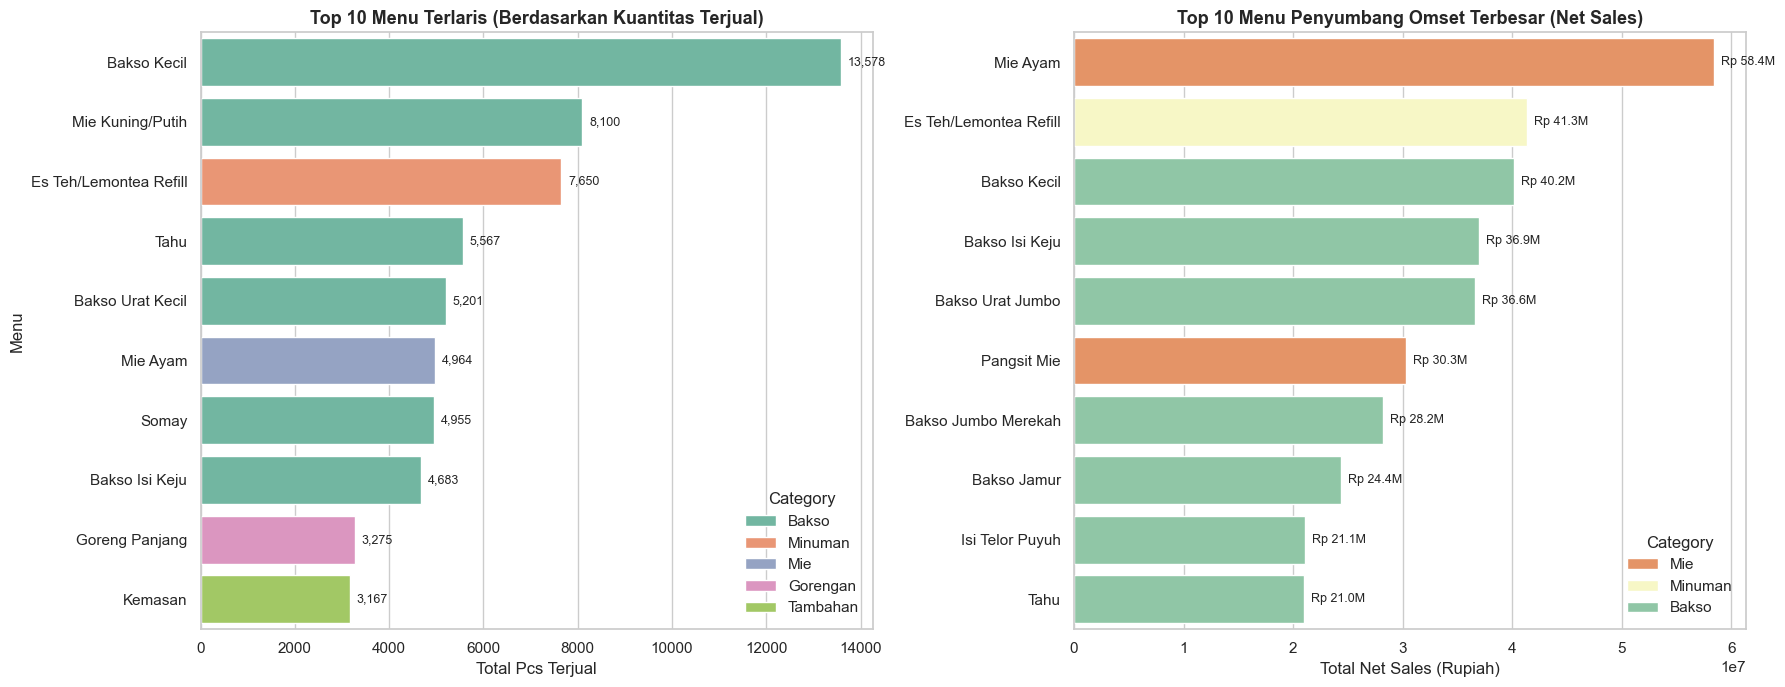

In [8]:
# Agregasi per Item
item_perf = df_clean.groupby(['Items', 'Category']).agg({
    'Quantity': 'sum',
    'Net Sales': 'sum'
}).reset_index()

top10_qty = item_perf.sort_values(by='Quantity', ascending=False).head(10)
top10_rev = item_perf.sort_values(by='Net Sales', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 10 Menu Terbanyak Terjual
sns.barplot(data=top10_qty, x='Quantity', y='Items', hue='Category', dodge=False, palette='Set2', ax=axes[0])
axes[0].set_title('Top 10 Menu Terlaris (Berdasarkan Kuantitas Terjual)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Pcs Terjual')
axes[0].set_ylabel('Menu')
for p in axes[0].patches:
    val = p.get_width()
    if val > 0:
        axes[0].annotate(f'{val:,.0f}', (val, p.get_y() + p.get_height()/2),
                         ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

# 10 Menu Omset Terbesar
sns.barplot(data=top10_rev, x='Net Sales', y='Items', hue='Category', dodge=False, palette='Spectral', ax=axes[1])
axes[1].set_title('Top 10 Menu Penyumbang Omset Terbesar (Net Sales)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Net Sales (Rupiah)')
axes[1].set_ylabel('')
for p in axes[1].patches:
    val = p.get_width()
    if val > 0:
        axes[1].annotate(f'Rp {val/1e6:.1f}M', (val, p.get_y() + p.get_height()/2),
                         ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


## 8. Analisis Tren Waktu (Monthly, Day of Week, & Peak Hours)
Menganalisis dinamika penjualan dari aspek waktu:
1. Tren bulanan (*Monthly Sales Trend*).
2. Pola penjualan hari dalam seminggu (*Day of Week Pattern*).
3. Jam operasional tersibuk (*Peak Hours*).


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_4218/1192726022.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=daily_pattern, x='Day_Name', y='Net Sales', palette='coolwarm', ax=ax2)
/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_4218/1192726022.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_pattern, x='Hour', y='Net Sales', palette='viridis', ax=ax3)


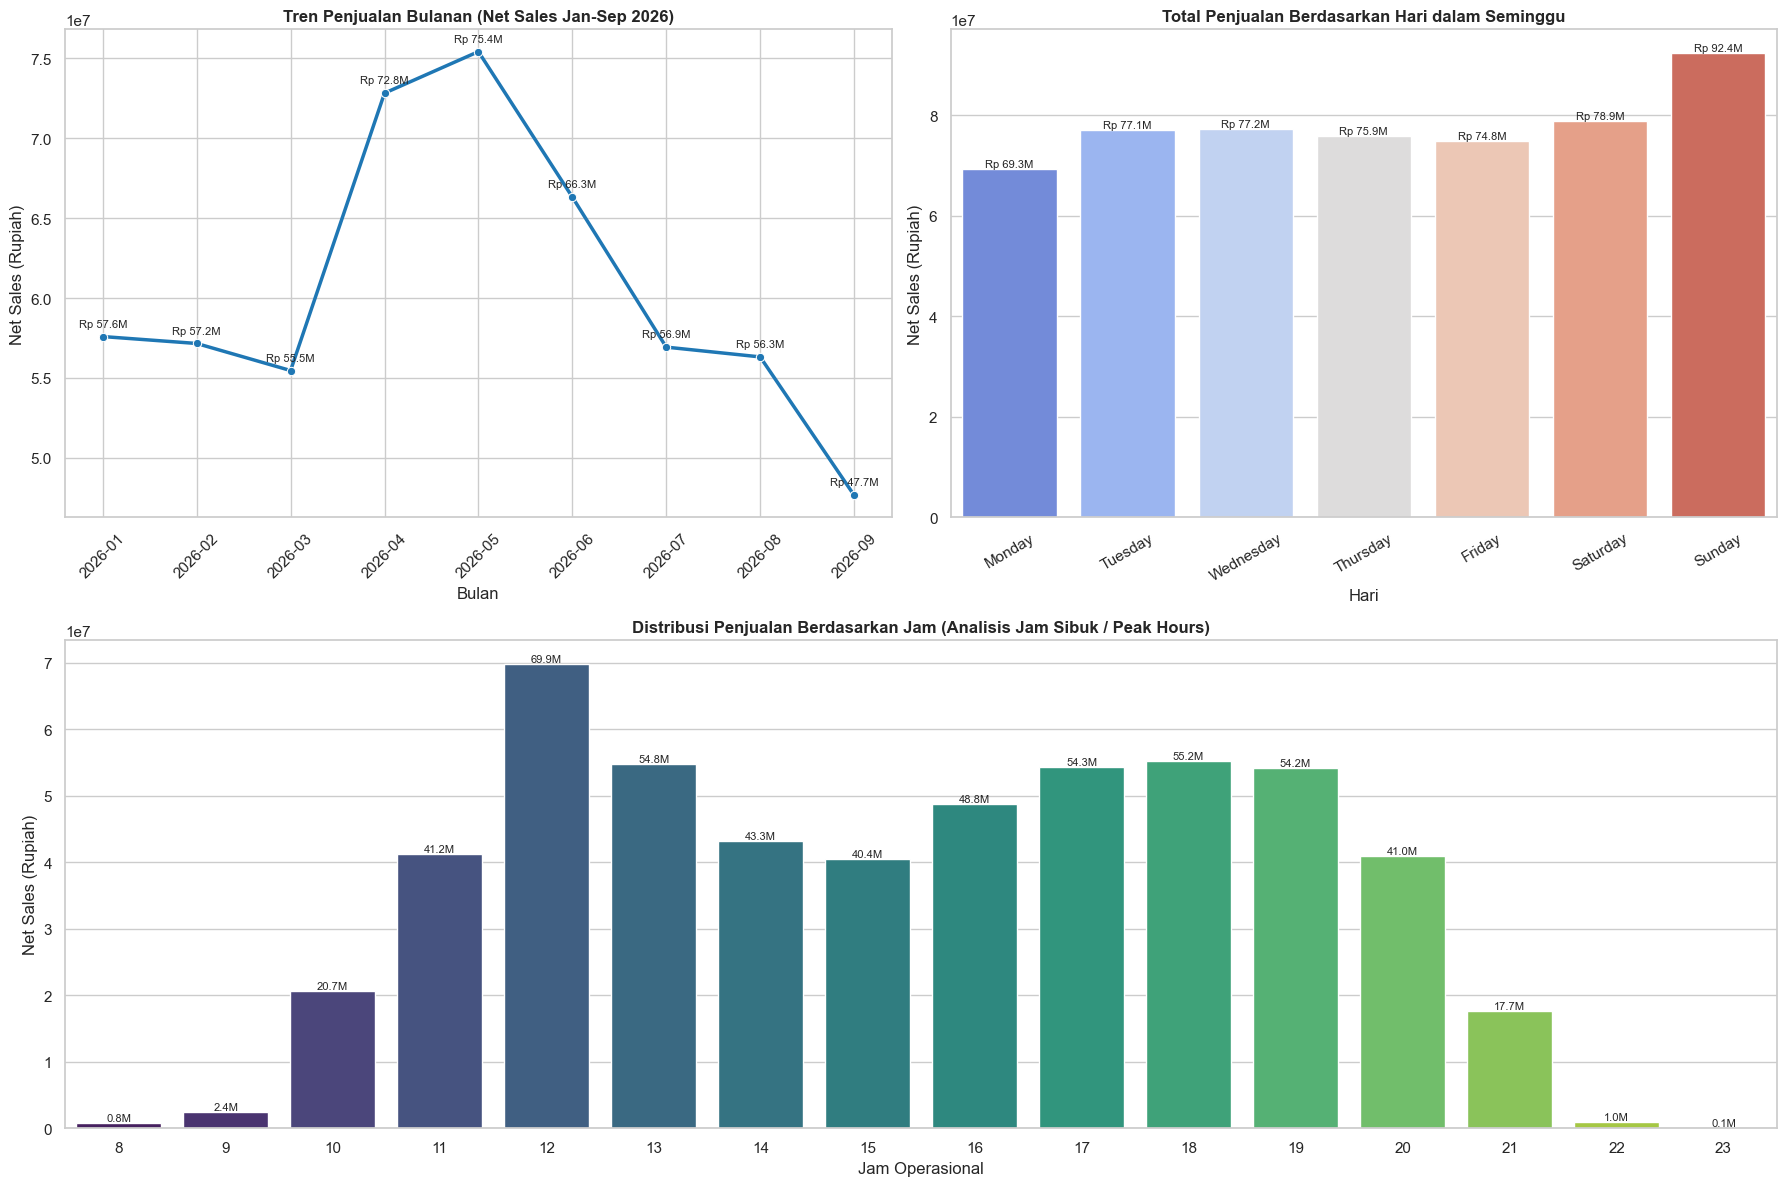

In [9]:
# Agregasi Tren Waktu
monthly_trend = df_clean.groupby('Month_Year')['Net Sales'].sum().reset_index()
monthly_trend['Month_Str'] = monthly_trend['Month_Year'].astype(str)

daily_pattern = df_clean.groupby('Day_Name', observed=False)['Net Sales'].sum().reset_index()
hourly_pattern = df_clean.groupby('Hour')['Net Sales'].sum().reset_index()

fig = plt.figure(figsize=(18, 12))

# Subplot 1: Tren Bulanan
ax1 = plt.subplot(2, 2, 1)
sns.lineplot(data=monthly_trend, x='Month_Str', y='Net Sales', marker='o', color='#1f77b4', linewidth=2.5, ax=ax1)
ax1.set_title('Tren Penjualan Bulanan (Net Sales Jan-Sep 2026)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Bulan')
ax1.set_ylabel('Net Sales (Rupiah)')
ax1.tick_params(axis='x', rotation=45)
for _, row in monthly_trend.iterrows():
    ax1.annotate(f'Rp {row["Net Sales"]/1e6:.1f}M', (row['Month_Str'], row['Net Sales']),
                 textcoords="offset points", xytext=(0, 7), ha='center', fontsize=8)

# Subplot 2: Pola Hari
ax2 = plt.subplot(2, 2, 2)
sns.barplot(data=daily_pattern, x='Day_Name', y='Net Sales', palette='coolwarm', ax=ax2)
ax2.set_title('Total Penjualan Berdasarkan Hari dalam Seminggu', fontsize=12, fontweight='bold')
ax2.set_xlabel('Hari')
ax2.set_ylabel('Net Sales (Rupiah)')
ax2.tick_params(axis='x', rotation=30)
for p in ax2.patches:
    val = p.get_height()
    ax2.annotate(f'Rp {val/1e6:.1f}M', (p.get_x() + p.get_width() / 2, val),
                 ha='center', va='bottom', fontsize=8)

# Subplot 3: Jam Sibuk (Hourly)
ax3 = plt.subplot(2, 1, 2)
sns.barplot(data=hourly_pattern, x='Hour', y='Net Sales', palette='viridis', ax=ax3)
ax3.set_title('Distribusi Penjualan Berdasarkan Jam (Analisis Jam Sibuk / Peak Hours)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Jam Operasional')
ax3.set_ylabel('Net Sales (Rupiah)')
for p in ax3.patches:
    val = p.get_height()
    if val > 0:
        ax3.annotate(f'{val/1e6:.1f}M', (p.get_x() + p.get_width() / 2, val),
                     ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


## 9. Analisis Kanal Penjualan & Metode Pembayaran
Mengetahui komposisi saluran penjualan (*Sales Type*: Dine In, GoFood, GrabFood, dll.) dan preferensi metode pembayaran pelanggan.


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_4218/2322879293.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_df, x='Net Sales', y='Payment Method', palette='Blues_d', ax=axes[1])


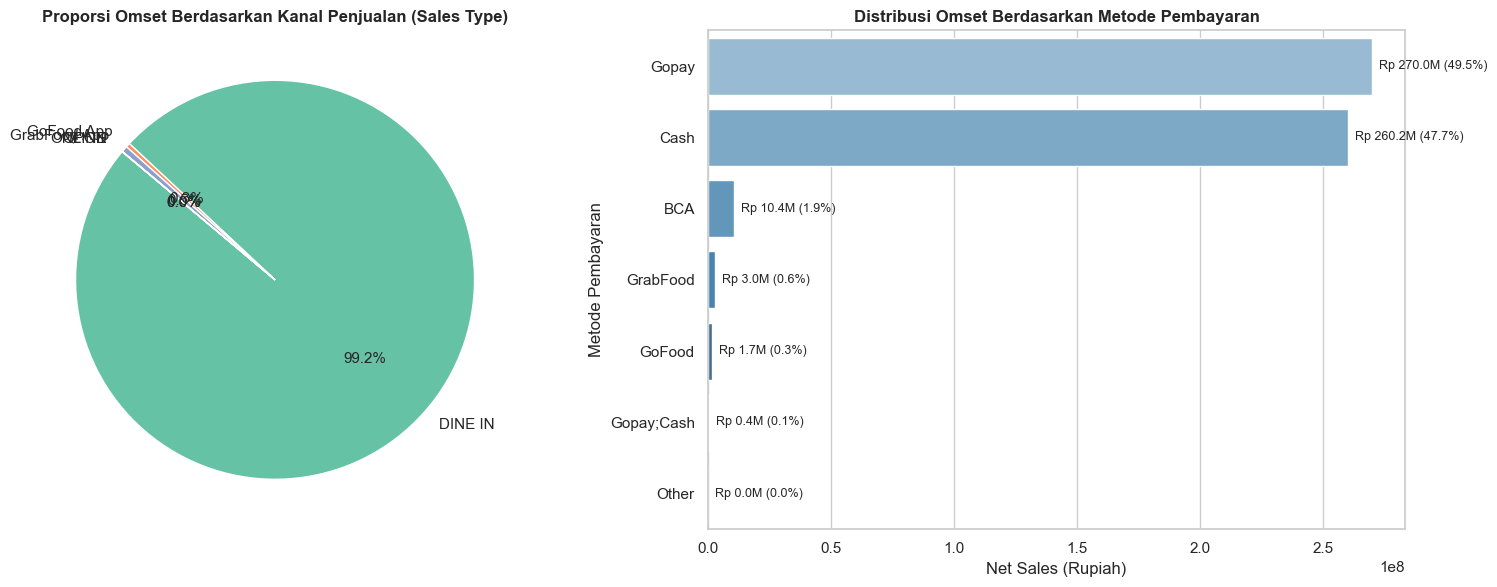

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Proporsi Tipe Penjualan
sales_type_df = df_clean.groupby('Sales Type')['Net Sales'].sum().reset_index()
axes[0].pie(
    sales_type_df['Net Sales'],
    labels=sales_type_df['Sales Type'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2')
)
axes[0].set_title('Proporsi Omset Berdasarkan Kanal Penjualan (Sales Type)', fontsize=12, fontweight='bold')

# Metode Pembayaran
payment_df = df_clean.groupby('Payment Method')['Net Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=payment_df, x='Net Sales', y='Payment Method', palette='Blues_d', ax=axes[1])
axes[1].set_title('Distribusi Omset Berdasarkan Metode Pembayaran', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Net Sales (Rupiah)')
axes[1].set_ylabel('Metode Pembayaran')
for p in axes[1].patches:
    val = p.get_width()
    axes[1].annotate(f'Rp {val/1e6:.1f}M ({val/total_net*100:.1f}%)', 
                     (val, p.get_y() + p.get_height()/2),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


## 10. Analisis Diskon & Refund
Menelaah seberapa besar efektivitas promo diskon dan tingkat pembatalan pesanan (*refund*).


In [11]:
# Analisis Diskon
discount_items = df_clean[df_clean['Discounts'] > 0]
print(f"Total baris transaksi dengan diskon: {len(discount_items):,} baris")
print(f"Total nominal diskon: Rp {df_clean['Discounts'].sum():,.2f}")

discount_breakdown = df_clean[df_clean['Discount Applied'].notnull() & (df_clean['Discount Applied'] != '')].groupby('Discount Applied').agg({
    'Discounts': 'sum',
    'Receipt Number': 'nunique'
}).sort_values(by='Discounts', ascending=False).reset_index()

print("\nBreakdown Diskon Berdasarkan Jenis Promo/Diskon:")
display(discount_breakdown)

# Analisis Refund
refund_items = df_clean[df_clean['Refunds'] > 0]
print(f"\nTotal nominal refund: Rp {df_clean['Refunds'].sum():,.2f} dari {len(refund_items):,} baris transaksi.")
if len(refund_items) > 0:
    top_refunded = refund_items.groupby('Items')['Refunds'].sum().sort_values(ascending=False).head(5)
    print("\nTop 5 Menu Paling Sering Di-refund:")
    display(top_refunded)


Total baris transaksi dengan diskon: 7,301 baris
Total nominal diskon: Rp 31,900,460.40

Breakdown Diskon Berdasarkan Jenis Promo/Diskon:


,Discount Applied,Discounts,Receipt Number
0,Discount Karyawan,9871124.82,997
1,Merekah Des,6804000.00,358
2,Discount Owner,3242000.00,102
3,Pangsit Des,2778000.00,341
4,Bakso pedas Des,2495000.00,451
5,Loyalty Reward Redemption,1338534.86,223
6,Discount Rupiah by Manager,910800.03,41
7,Voucher 25 rb,900000.10,18
8,Mar-Pangsit Free Es Teh,762000.00,95
9,Hotplate Des,678000.00,91



Total nominal refund: Rp 1,676,000.00 dari 165 baris transaksi.

Top 5 Menu Paling Sering Di-refund:


Items
Full Refund for: 3BOP7H - Mie Ayam               84000.0
Partial Refund for: 3BOUYX - Es Teler Regular    60000.0
Full Refund for: 3BOMQT - Bakso Jumbo Merekah    54000.0
Full Refund for: 3BOS6K - Mie Ayam               48000.0
Full Refund for: 3BOUPD - Es Teler Regular       46000.0
Name: Refunds, dtype: float64

## 11. Kesimpulan & Ringkasan Analisis (Executive Summary)

### Data Analysis Key Findings
- **Total Omset & Transaksi**: Selama periode Januari hingga September 2026, tercatat total **12.238 transaksi unik** dengan omset kotor (*Gross Sales*) sebesar **Rp 579,30 Juta** dan omset bersih (*Net Sales*) sebesar **Rp 545,72 Juta** setelah potongan diskon (Rp 31,90 Juta) dan refund (Rp 1,68 Juta).
- **Rata-rata Transaksi (AOV)**: Nilai rata-rata belanja konsumen (*Average Order Value*) berada di angka **Rp 44.592** per struk transaksi dengan rata-rata pembelian **~5.2 item**.
- **Kategori Dominan**: Kategori **Bakso** merupakan kontributor pendapatan terbesar yakni mencapai **Rp 311,27 Juta (57,0%)**, diikuti oleh **Mie** sebesar **Rp 97,52 Juta (17,9%)**, dan **Minuman** sebesar **Rp 72,97 Juta (13,4%)**.
- **Menu Terlaris (Hero Products)**: Produk dengan kuantitas penjualan tertinggi adalah **Bakso Kecil (13.578 pcs)**, **Mie Kuning/Putih (8.100 pcs)**, dan **Es Teh/Lemontea Refill (7.650 pcs)**.
- **Pola Waktu & Peak Hours**: Jam transaksi terpadat terjadi pada jam makan siang (**12:00 - 14:00**) dan puncaknya pada jam makan malam (**18:00 - 20:00**). Hari Sabtu dan Minggu mencatatkan lonjakan volume penjualan tertinggi dibanding hari kerja.
- **Kanal & Metode Pembayaran**: Penjualan mayoritas masih didominasi oleh kanal **DINE IN**, sedangkan metode pembayaran non-tunai (Gopay/QRIS) dan tunai (Cash) memegang porsi transaksi terbesar.

### Insights or Next Steps
- **Cross-Selling & Paket Bundling**: Mengingat tingginya volume penjualan Bakso Kecil dan Es Teh Refill, buat menu paket bundling hemat (contoh: *"Paket Puas Bakso + Minum"*) untuk mendongkrak *Average Order Value* (AOV) di atas Rp 50.000.
- **Optimasi Shift di Jam Sibuk (Peak Hours)**: Optimalkan jadwal staf dan persiapan bahan baku setengah jadi sebelum jam makan malam (18:00 - 20:00) dan akhir pekan (Sabtu & Minggu) untuk meminimalkan antrean dan meningkatkan kepuasan pelanggan.
